# Real Steam Review Feasibility Pilot — Civilization VI

**Study stage:** exploratory feasibility check, not a representative study. **As of:** November 15, 2026.

**Sources:** [Steam Community · Most helpful negative English reviews](https://steamcommunity.com/app/289070/negativereviews/?browsefilter=toprated&l=english&p=1) and [Steam Community · Most recent negative English reviews](https://steamcommunity.com/app/289070/negativereviews/?browsefilter=mostrecent&l=english&p=1). The pages were available from web-cached copies, rather than a successful live API response. The 20 reviews below were *manually inspected and paraphrased*, not downloaded through the API. The webpage's 'hours on record' are **not** necessarily playtime at original review time.

A separate public aggregated monthly review history is provided by [charts.game](https://charts.game/games/289070-sid-meiers-civilization-vi/reviews), sourced from Steam's monthly review graph. Its counts cover **all review languages and Steam graph conventions**, not the 20 coded reviews or necessarily the English-purchaser-only population.

**Research question for the full study:** How often do negative reviews name a specific problem or request a change, and which categories of issues appear?

## Data scope and manual coding

Two visible pages were inspected: 10 most-helpful and 10 most-recent negative English reviews on the cached pages. Review order and wording may have changed since the pages were cached; the month/day-only timestamps on the most-recent page do not show a year. To avoid redistributing user text, this CSV contains **paraphrased summaries**, dates displayed on the pages, current displayed playtime and coding labels, without usernames or Steam IDs.

Codes: `F0` general reaction, `F1` identifiable issue, `F2` explicit requested change, `F3` specific solution. **Highest applicable level** is recorded per review; topics permit multiple labels. These are preliminary single-coder judgments and should not be used to assert broader prevalence.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

base = Path('.')
pilot = pd.read_csv(base / 'pilot_20_annotated_summaries.csv')
monthly = pd.read_csv(base / 'steam_monthly_counts_public_aggregate.csv')
print('Visible Steam reviews coded:', len(pilot))
print('Feedback-level counts:')
print(pilot.feedback_level.value_counts().reindex(['F0','F1','F2','F3'],fill_value=0))
print('Explicit change/request level F2/F3:', pilot.feedback_level.isin(['F2','F3']).sum())
print('By selection mode:')
print(pd.crosstab(pilot.selection, pilot.feedback_level))

Visible Steam reviews coded: 20
Feedback-level counts:
feedback_level
F0     2
F1    14
F2     2
F3     2
Name: count, dtype: int64
Explicit change/request level F2/F3: 4
By selection mode:
feedback_level  F0  F1  F2  F3
selection                     
most_helpful     0   8   1   1
most_recent      2   6   1   1


topic
privacy_terms            11
technical_performance     6
other                     3
launcher                  2
gameplay_mechanics        2
balance                   2
Name: count, dtype: int64


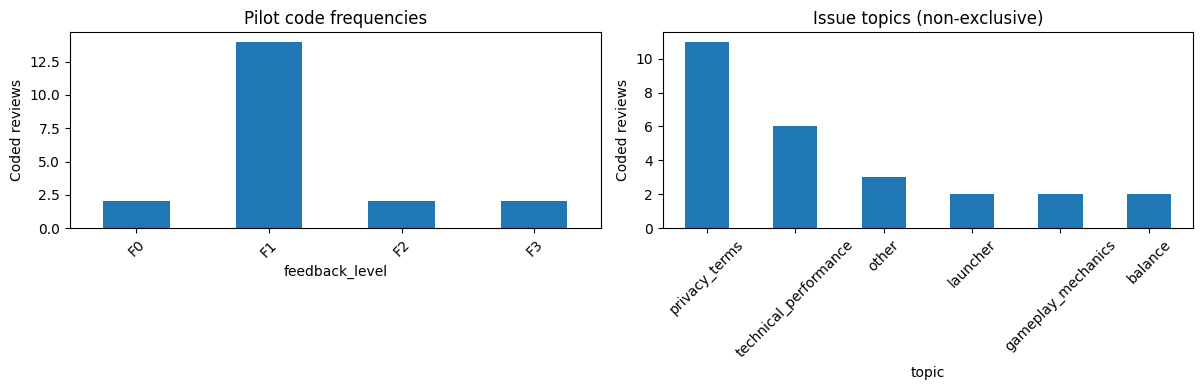

In [2]:
topics = pilot.assign(topic=pilot.issue_topics.str.split(';')).explode('topic')
print(topics.topic.value_counts())
fig, axs = plt.subplots(1,2,figsize=(12,4))
pilot.feedback_level.value_counts().reindex(['F0','F1','F2','F3']).plot.bar(ax=axs[0],title='Pilot code frequencies')
topics.topic.value_counts().plot.bar(ax=axs[1],title='Issue topics (non-exclusive)')
for a in axs: a.set_ylabel('Coded reviews'); a.tick_params(axis='x',rotation=45)
plt.tight_layout()

## Public monthly review counts: a critical sampling warning

Unlike the pilot above, the monthly counts are aggregated **all-language** Steam review-history data via charts.game. They are not individual-level comments. This second source is only used to explore historical shifts in the review population and check whether a proposed review period looks unusually volatile.

  month  positive_reviews  negative_reviews  negative_share_pct
2025-05              1221               160                11.6
2025-06              1320              3184                70.7
2025-07              1707               664                28.0
2026-10               944               106                10.1


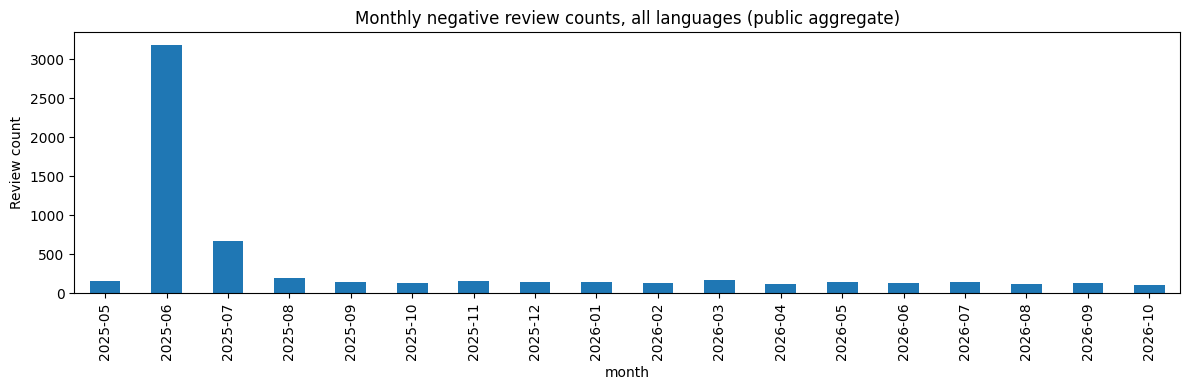

In [3]:
monthly['negative_share_pct'] = (100*monthly.negative_reviews/monthly.total_reviews).round(1)
print(monthly.loc[monthly.month.isin(['2025-05','2025-06','2025-07','2026-10']),['month','positive_reviews','negative_reviews','negative_share_pct']].to_string(index=False))
ax=monthly.plot.bar(x='month',y='negative_reviews',figsize=(12,4),legend=False,title='Monthly negative review counts, all languages (public aggregate)')
ax.set_ylabel('Review count')
plt.tight_layout()

## Observations and limitations

- **Observed in the 20 selected texts:** 14 were coded `F1`, 2 `F0`, 2 `F2` and 2 `F3`. Thus 4/20 contained an explicit requested change or more detailed solution, **only within this convenience pilot**. These counts rely on single-coder judgment.
- The most-helpful sample was heavily focused on EULA/privacy/publisher issues; the most-recent sample included more game mechanics, stability and brief remarks. **This is evidence of selection-context differences, not an unbiased estimate of either population.**
- The monthly source shows **3,184 negative reviews in June 2025**, compared with 160 in May 2025 and 664 in July 2025; June's share negative is approximately 70.7%. This could distort an unrestricted time-series or keyword analysis. The fact that high-ranked 2025 reviews discuss revised EULA terms makes that **a plausible context**, but it does not establish the sole cause of the spike.
- **No inference about frequency of actionable feedback across all Civilization VI reviews is supported yet.** The official API collection, representative sampling and coding reliability checks remain needed.
- For A5's planned main study, a post-wave, bounded review window (May–October 2026) remains a sensible baseline; retain policy/privacy and launcher issues as potential topics rather than silently excluding them.
- Steam Community pages expose displayed *hours on record*, which should not be substituted for the official API's `author.playtime_at_review`. Review text may have been edited after the posted date.

**Source audit:** All review summaries were manually transcribed as paraphrases from the two public pages above, and the aggregate numbers were taken from the charts.game Steam-history table. These are the only actual observations claimed here. API access from the execution environment failed due to network restrictions; no unseen reviews were fabricated.